In [5]:
pvalues = [1, 0.5, 0.75]
def findp(n):
    global pvalues
    if len(pvalues) >= n:
        return pvalues[n-1]
    else:
        newval = (0.5*findp(n-2)) + (0.5*findp(n-1))
        pvalues.append(newval)
        return newval
findp(26)
print(f"n = 1: {pvalues[0]}\n n = 2: {pvalues[1]} \n n = 3: {pvalues[2]} \n n = 4: {pvalues[3]} \n ... \n n = 26: {pvalues[25]}")

n = 1: 1
 n = 2: 0.5 
 n = 3: 0.75 
 n = 4: 0.625 
 ... 
 n = 26: 0.6666666567325592


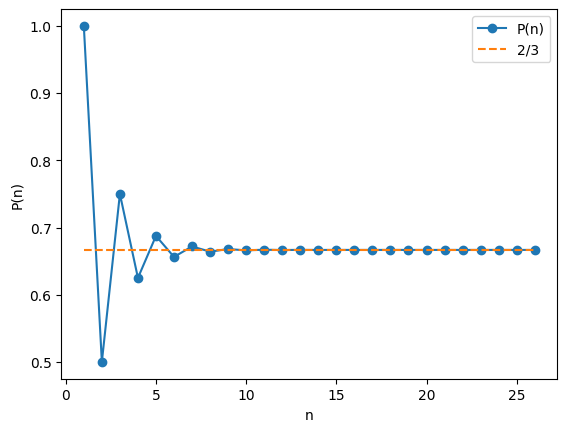

In [23]:
import numpy as np
import matplotlib.pyplot as plt
x = [i for i in range(1, 27)]
plt.plot(x, pvalues, marker='o', label="P(n)")
plt.plot(x, [2/3 for i in range(len(x))], linestyle = "--", label="2/3")
plt.xlabel("n")
plt.ylabel("P(n)")
plt.legend()

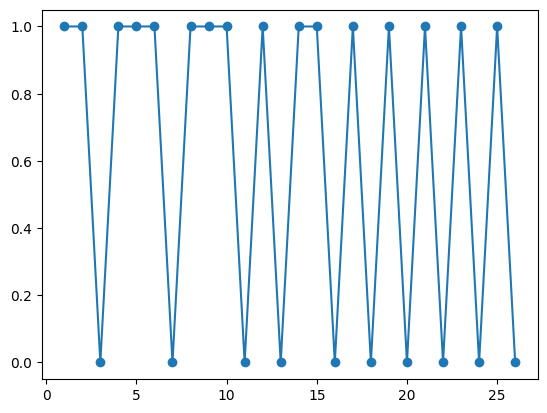

In [62]:
import random as rdm

#The code for generating a walk, and a graph showing what one walk looks like

def nextstep(n):
    if rdm.random() < 0.5:
        return n+1
    return n+2

def genwalk():
    walk = [0 for i in range(26)]
    n = 0
    while n < len(walk):
        walk[n] = 1
        n = nextstep(n)
    return walk

x = [i for i in range(1, 27)]
plt.plot(x, genwalk(), marker='o')
plt.show()

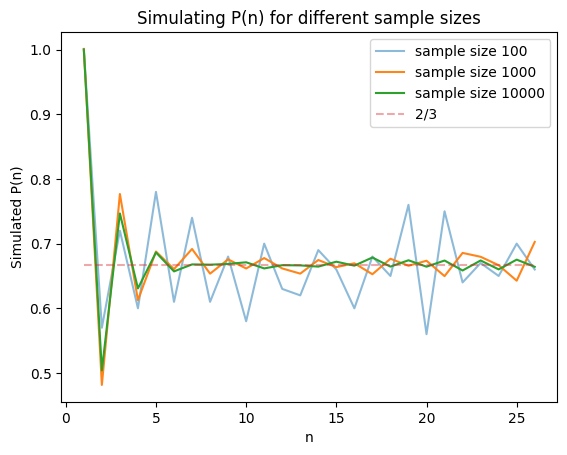

In [93]:
x = [i for i in range(1, 27)]
freq = [0 for i in range(26)]

#Now we generate multiple walks, record how often we land on each number, and normalise to see what probability we should get

def record(x):
    global freq
    for i in range(len(freq)):
        freq[i] += x[i]

def normalise(n):
    global freq
    for i in range(len(freq)):
        freq[i] = freq[i] / n

def simruns(n):
    for i in range(n):
        record(genwalk())
    normalise(n)
    plt.plot(x, freq, label=f"sample size {n}", alpha=(1-50/n))
    



#Let's run a few different sample sizes and see what we get

simruns(100)
simruns(1000)
simruns(10000)
plt.title("Simulating P(n) for different sample sizes")
plt.xlabel("n")
plt.ylabel("Simulated P(n)")
plt.plot(x, [2/3 for i in range(len(x))], linestyle = "--", label="2/3", alpha=0.4)
plt.legend()
plt.show()